In [140]:
import deap
import numpy as np
from deap import algorithms, base, creator, tools
SEED = 42
import random

### Does cooperation emerge and remain stable in an evolving population, and how does the answer depend on the noise level?

In [141]:
NOISE_LEVELS = [0, 0.01, 0.05]
# all combinations of 5 bits
STRATEGIES = [tuple([int(l) for l in format(i, '05b')]) for i in range(32)]
rng = np.random.default_rng(SEED)

In [142]:
# name the classic strategies
CLASSICS = {
    (0, 0, 0, 0, 0): "ALLC",     # always cooperate
    (1, 1, 1, 1, 1): "ALLD",     # always defect   
    (0, 0, 1, 0, 1): "TFT",      # tit for tat, start cooperatively
    (0, 0, 1, 1, 0): "PAVLOV",   # win-stay lose-shift, start C
    (0, 0, 1, 1, 1): "GRIM",     # start cooperative, take any betrayal to heart and spam defect
    (1, 0, 1, 0, 1): "STFT",     # suspicious tit for tat
}

In [143]:
P1_HEAD_TO_HEAD = np.array([[3, 0], [5, 1]]) # outcomes for p1 in prisoners dilemma

#### Compute expected payoff matrix

In [144]:
# Payoff conditional on the previous outcome; player 2 uses their own perspective.
n = len(STRATEGIES)
PAYOFFS = np.zeros((n, n, 4))
for i in range(n):
    for j in range(n):
        for outcome in range(4):
            p1_action = STRATEGIES[i][outcome + 1]
            p2_outcome = [0, 2, 1, 3][outcome] # player two perspective has CD and DC flipped
            p2_action = STRATEGIES[j][p2_outcome + 1]
            PAYOFFS[i, j, outcome] = P1_HEAD_TO_HEAD[p1_action, p2_action]


In [145]:
def bits_to_id(bits):
    return int("".join(str(i) for i in bits), 2)

BITS_TO_IDS = { strat : bits_to_id(strat) for strat in STRATEGIES}

In [146]:
BITS_TO_IDS

{(0, 0, 0, 0, 0): 0,
 (0, 0, 0, 0, 1): 1,
 (0, 0, 0, 1, 0): 2,
 (0, 0, 0, 1, 1): 3,
 (0, 0, 1, 0, 0): 4,
 (0, 0, 1, 0, 1): 5,
 (0, 0, 1, 1, 0): 6,
 (0, 0, 1, 1, 1): 7,
 (0, 1, 0, 0, 0): 8,
 (0, 1, 0, 0, 1): 9,
 (0, 1, 0, 1, 0): 10,
 (0, 1, 0, 1, 1): 11,
 (0, 1, 1, 0, 0): 12,
 (0, 1, 1, 0, 1): 13,
 (0, 1, 1, 1, 0): 14,
 (0, 1, 1, 1, 1): 15,
 (1, 0, 0, 0, 0): 16,
 (1, 0, 0, 0, 1): 17,
 (1, 0, 0, 1, 0): 18,
 (1, 0, 0, 1, 1): 19,
 (1, 0, 1, 0, 0): 20,
 (1, 0, 1, 0, 1): 21,
 (1, 0, 1, 1, 0): 22,
 (1, 0, 1, 1, 1): 23,
 (1, 1, 0, 0, 0): 24,
 (1, 1, 0, 0, 1): 25,
 (1, 1, 0, 1, 0): 26,
 (1, 1, 0, 1, 1): 27,
 (1, 1, 1, 0, 0): 28,
 (1, 1, 1, 0, 1): 29,
 (1, 1, 1, 1, 0): 30,
 (1, 1, 1, 1, 1): 31}

### Define evaluation function
Do round robin against all other individuals in population

In [147]:
P2_OUTCOME_MAP = [0, 2, 1, 3] # CD <=> DC from p2 perspective
# first need game function to incorporate noise
def game(last_outcome, p1, p2, noise, rng, h2h):
    if last_outcome is None: # go with first move for strat
        p1_intended = p1[0]
        p2_intended = p2[0]
    else:
        p1_intended = p1[last_outcome + 1]
        p2_intended = p2[P2_OUTCOME_MAP[last_outcome] + 1]
    # players make moves based on last outcome but with p(error) = noise
    p1_move = p1_intended if rng.random() > noise else 1 - p1_intended
    p2_move = p2_intended if rng.random() > noise else 1 - p2_intended
    new_outcome = 2 * p1_move + p2_move # CC = 0, CD = 1, DC = 2, DD = 3
    return h2h[p1_move, p2_move], new_outcome    


In [148]:
N_ROUNDS = 150
N_MATCH_REPLICATES = 20  # independent noisy matches per strategy pair
# DEAP calls evaluate(ind) only, so opponents/noise live here.
# Each generation, set current_pop[:] = pop before evaluating.
current_pop = []
current_noise = 0.0

def play_match(p1, p2, noise, rng, h2h, n_rounds=N_ROUNDS):
    last_outcome = None
    total = 0.0
    for _ in range(n_rounds):
        payoff, last_outcome = game(last_outcome, p1, p2, noise, rng, h2h)
        total += payoff
    return total / n_rounds


In [149]:
# Estimate each ordered matchup's expected payoff with independent trajectories.
PAYOFF_SEED = SEED + 100_000
payoff_rng = np.random.default_rng(PAYOFF_SEED)
NOISE_PAYOFFS = {noise: np.zeros((len(STRATEGIES), len(STRATEGIES))) for noise in NOISE_LEVELS}

for noise in NOISE_LEVELS:
    for i, strategy_i in enumerate(STRATEGIES):
        for j, strategy_j in enumerate(STRATEGIES):
            samples = [
                play_match(strategy_i, strategy_j, noise, payoff_rng, P1_HEAD_TO_HEAD)
                for _ in range(N_MATCH_REPLICATES)
            ]
            NOISE_PAYOFFS[noise][i, j] = np.mean(samples)


def round_robin_evaluate(ind, population=None, noise=None):
    # this functions plays an individual against all other competitors in its generation to measure its fitness

    # use current population and current noise global vars to get around tb.evaluate()'s single arg
    if population is None:
        population = current_pop
    if noise is None:
        noise = current_noise
    competitors = [competitor for competitor in population if competitor is not ind] # exclude ind from people to play against
    if not competitors:
        return (0.0,)
    ind_index = BITS_TO_IDS[tuple(ind)]
    scores = [NOISE_PAYOFFS[noise][ind_index, BITS_TO_IDS[tuple(c)]] for c in competitors]
    return (float(np.mean(scores)),)


In [153]:
import csv
import random
from pathlib import Path

import matplotlib.pyplot as plt
from deap import base, creator, tools, algorithms

try:
    del creator.FitnessMax
    del creator.Individual
except Exception:
    pass

creator.create("FitnessMax", base.Fitness, weights=(1.0,))
creator.create("Individual", list, fitness=creator.FitnessMax)

# Define constants for running the experiments using suggested defaults
N_RUNS = 10
POP_SIZE = 100
N_GENERATIONS = 500
CXPB = 0.7
MUTPB = 1.0 # keep this 1 as indpb controls bit flipping mutations
MUTATION_INDPB = 0.01
TOURNAMENT_SIZE = 3
ELITE_SIZE = 2
ROLLING_WINDOW = 11  # used for plots only; raw generation values are saved
OUTPUT_DIR = Path("evolution_results")

tb = base.Toolbox()
tb.register("bit", random.randint, 0, 1)
tb.register("individual", tools.initRepeat, creator.Individual, tb.bit, n=5)
tb.register("population", tools.initRepeat, list, tb.individual)
tb.register("evaluate", round_robin_evaluate)
tb.register("mate", tools.cxOnePoint)
tb.register("mutate", tools.mutFlipBit, indpb=MUTATION_INDPB)
tb.register("select", tools.selTournament, tournsize=TOURNAMENT_SIZE)

# Keep the same seed schedule at each noise level for paired comparisons.
RUN_SEEDS = [SEED + run_idx for run_idx in range(N_RUNS)]

def strategy_frequencies(pop):
    ids = [BITS_TO_IDS[tuple(ind)] for ind in pop]
    return np.bincount(ids, minlength=len(STRATEGIES)) / len(pop)


def run_evolution(noise, seed):
    global current_noise
    current_noise = noise
    random.seed(seed)
    pop = tb.population(n=POP_SIZE)
    current_pop[:] = pop
    for ind in pop:
        ind.fitness.values = tb.evaluate(ind)

    mean_payoff = [float(np.mean([ind.fitness.values[0] for ind in pop]))]
    best_payoff = [float(max(ind.fitness.values[0] for ind in pop))]
    hist_freq = [strategy_frequencies(pop)]

    # Run the full horizon so generation-by-generation records are comparable.
    # Elites preserve genotypes; their fitness is recalculated in each new population.
    for _ in range(N_GENERATIONS):
        elites = tools.selBest(pop, ELITE_SIZE)
        offspring = algorithms.varAnd(
            tb.select(pop, len(pop)), tb, cxpb=CXPB, mutpb=MUTPB
        )
        for i, elite in enumerate(elites):
            offspring[i] = tb.clone(elite)

        # Invalidate all offspring's fitness value so it can be recalculated against the current generation
        for ind in offspring:
            if ind.fitness.valid:
                del ind.fitness.values
        current_pop[:] = offspring
        for ind in offspring:
            ind.fitness.values = tb.evaluate(ind)
        pop = offspring

        generation_scores = np.array([ind.fitness.values[0] for ind in pop])
        mean_payoff.append(float(generation_scores.mean()))
        best_payoff.append(float(generation_scores.max()))
        hist_freq.append(strategy_frequencies(pop))

    final_leader = int(np.argmax(hist_freq[-1]))
    return {
        "noise": noise,
        "seed": seed,
        "mean_payoff": np.array(mean_payoff),
        "best_payoff": np.array(best_payoff),
        "freq": np.array(hist_freq),
        "final_leader": STRATEGIES[final_leader],
        "final_leader_frequency": float(hist_freq[-1][final_leader]),
    }


results = {
    noise: [run_evolution(noise, seed) for seed in RUN_SEEDS]
    for noise in NOISE_LEVELS
}


Saved 15030 generation records and 30 run records to evolution_results/


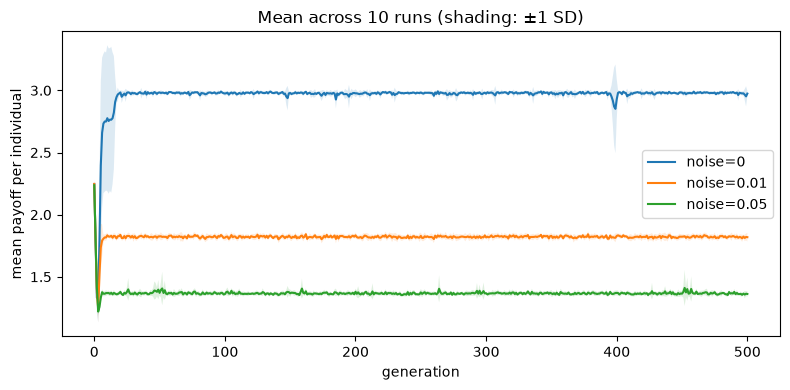

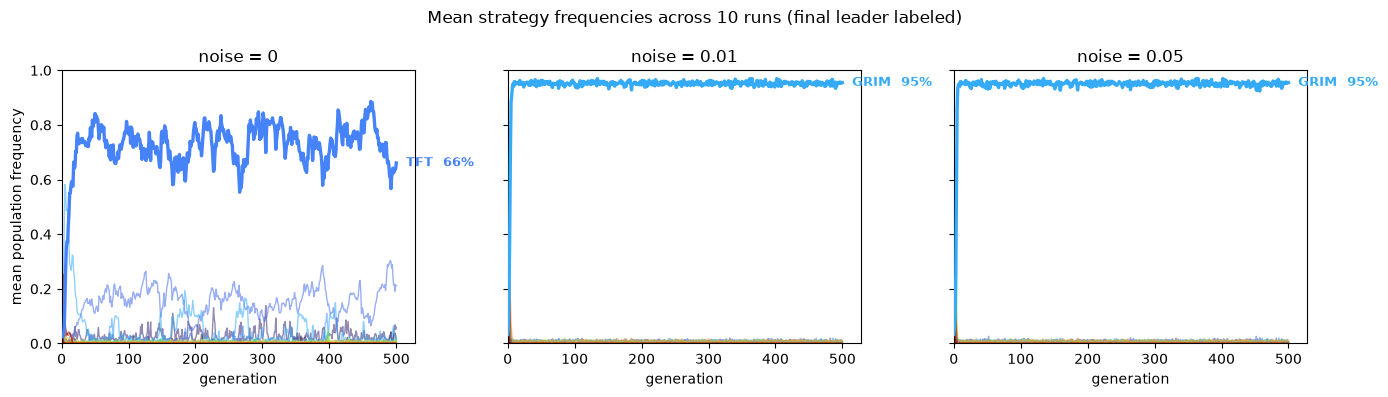

In [157]:
# Save one row per run and generation, including strategy frequencies and all run parameters.
OUTPUT_DIR.mkdir(exist_ok=True)
strategy_columns = ["freq_" + "".join(map(str, strategy)) for strategy in STRATEGIES]
generation_rows = []
run_rows = []
for noise, runs in results.items():
    for run_idx, run in enumerate(runs):
        run_rows.append({
            "noise": noise,
            "run": run_idx + 1,
            "evolution_seed": run["seed"],
            "final_leader": "".join(map(str, run["final_leader"])),
            "final_leader_frequency": run["final_leader_frequency"],
        })
        for generation in range(N_GENERATIONS + 1):
            row = {
                "noise": noise,
                "run": run_idx + 1,
                "evolution_seed": run["seed"],
                "generation": generation,
                "mean_payoff": run["mean_payoff"][generation],
                "best_payoff": run["best_payoff"][generation],
            }
            row.update(dict(zip(strategy_columns, run["freq"][generation])))
            generation_rows.append(row)

with (OUTPUT_DIR / "generation_data.csv").open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=generation_rows[0].keys())
    writer.writeheader()
    writer.writerows(generation_rows)
with (OUTPUT_DIR / "run_metadata.csv").open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=run_rows[0].keys())
    writer.writeheader()
    writer.writerows(run_rows)
print(f"Saved {len(generation_rows)} generation records and {len(run_rows)} run records to {OUTPUT_DIR}/")

# Plot smoothed mean population payoff across runs; raw values remain in the CSV.
fig, ax = plt.subplots(figsize=(8, 4))
for noise, runs in results.items():
    payoffs = np.array([run["mean_payoff"] for run in runs])
    # kernel = np.ones(ROLLING_WINDOW) / ROLLING_WINDOW
    # smoothed = np.array([np.convolve(row, kernel, mode="valid") for row in payoffs])
    # generations = np.arange(ROLLING_WINDOW - 1, N_GENERATIONS + 1)
    # mean = smoothed.mean(axis=0)
    # sd = smoothed.std(axis=0)
    # ax.plot(generations, mean, label=f"noise={noise}")
    # ax.fill_between(generations, mean - sd, mean + sd, alpha=0.15)
    mean = payoffs.mean(axis=0)
    sd = payoffs.std(axis=0)
    ax.plot(np.arange(N_GENERATIONS + 1), mean, label=f"noise={noise}")
    ax.fill_between(np.arange(N_GENERATIONS + 1), mean - sd, mean + sd, alpha=0.15)
ax.set_xlabel("generation")
ax.set_ylabel("mean payoff per individual")
ax.set_title(f"Mean across {N_RUNS} runs (shading: ±1 SD)")
ax.legend()
fig.tight_layout()
plt.show()

# Plot mean strategy frequencies; colors are consistent across noise panels.
fig, axes = plt.subplots(1, len(NOISE_LEVELS), figsize=(14, 4), sharey=True)
strategy_colors = plt.get_cmap("turbo", len(STRATEGIES))
for ax, noise in zip(axes, NOISE_LEVELS):
    freq = np.mean([run["freq"] for run in results[noise]], axis=0)
    final_leader = int(np.argmax(freq[-1]))
    for k in range(len(STRATEGIES)):
        is_leader = k == final_leader
        ax.plot(
            freq[:, k],
            color=strategy_colors(k),
            linewidth=2.4 if is_leader else 1.0,
            alpha=1.0 if is_leader else 0.55,
            zorder=3 if is_leader else 1,
        )
    leader = STRATEGIES[final_leader]
    leader_name = CLASSICS.get(leader, "".join(map(str, leader)))
    ax.annotate(
        f"{leader_name}  {freq[-1, final_leader]:.0%}",
        xy=(N_GENERATIONS, freq[-1, final_leader]),
        xytext=(7, 0),
        textcoords="offset points",
        color=strategy_colors(final_leader),
        fontsize=9,
        fontweight="bold",
        va="center",
        clip_on=False,
    )
    ax.set_title(f"noise = {noise}")
    ax.set_xlabel("generation")
    ax.set_ylim(0, 1)
    ax.set_xlim(0, N_GENERATIONS + 28)
axes[0].set_ylabel("mean population frequency")
fig.suptitle("Mean strategy frequencies across 10 runs (final leader labeled)")
fig.tight_layout()
plt.show()

In [151]:
run_rows[:5]

[{'noise': 0,
  'run': 1,
  'evolution_seed': 42,
  'payoff_seed': 100042,
  'match_replicates': 20,
  'n_rounds_per_match': 150,
  'population_size': 100,
  'n_generations': 500,
  'crossover_probability': 0.7,
  'mutation_probability': 1.0,
  'mutation_bit_probability': 0.01,
  'tournament_size': 3,
  'elite_size': 2,
  'final_leader': '00101',
  'final_leader_frequency': 0.89},
 {'noise': 0,
  'run': 2,
  'evolution_seed': 43,
  'payoff_seed': 100042,
  'match_replicates': 20,
  'n_rounds_per_match': 150,
  'population_size': 100,
  'n_generations': 500,
  'crossover_probability': 0.7,
  'mutation_probability': 1.0,
  'mutation_bit_probability': 0.01,
  'tournament_size': 3,
  'elite_size': 2,
  'final_leader': '00100',
  'final_leader_frequency': 0.67},
 {'noise': 0,
  'run': 3,
  'evolution_seed': 44,
  'payoff_seed': 100042,
  'match_replicates': 20,
  'n_rounds_per_match': 150,
  'population_size': 100,
  'n_generations': 500,
  'crossover_probability': 0.7,
  'mutation_probabil